In [ ]:
# Model name: microsoft/resnet-18
# Task: Image classification
# Platform: Hugging Face
# Library: Transformers
#Execution: Local Jupyter Notebook 

In [15]:

import importlib.util
import sys

print("Python executable:", sys.executable)

# Check required libraries
for package in ["torch", "transformers", "PIL"]:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'Installed' if installed else 'Missing'}")


Python executable: C:\ProgramData\anaconda3\python.exe
torch: Installed
transformers: Installed
PIL: Installed


In [16]:
# Install Hugging Face Transformers
%pip install transformers

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [17]:
# Install image processing library
%pip install pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [18]:
# Install deep learning library
%pip install torch

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
# Import and check library versions
import torch
import transformers
from PIL import Image

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("All libraries are working!")

PyTorch: 2.14.1+cpu
Transformers: 5.20.2
All libraries are working!


In [20]:
# Load ResNet-18 for image classification
from transformers import pipeline

classifier = pipeline(
    "image-classification",
    model="microsoft/resnet-18",
    device=-1
)

print("Model loaded successfully!")

Could not reach the Hub ([WinError 10054] An existing connection was forcibly closed by the remote host). Using cached commit hash for 'microsoft/resnet-18'.


Loading weights:   0%|          | 0/122 [00:00<?, ?it/s]

Model loaded successfully!


In [22]:
# Check whether the image exists
from IPython.display import display
from PIL import Image
from pathlib import Path

image_path = Path("elephant.jpg")

print("Current folder:", Path.cwd())
print("Image exists:", image_path.exists())

Current folder: D:\basic python
Image exists: False


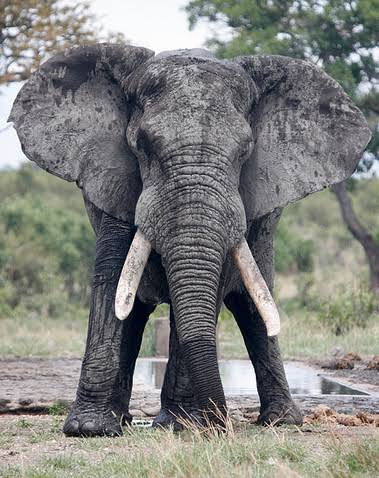

Image loaded successfully!


In [23]:
# Select and display an image from your pc
from tkinter import Tk, filedialog
from PIL import Image
from IPython.display import display

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_path = filedialog.askopenfilename(
    title="Select an image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png"),
        ("All files", "*.*")
    ]
)

root.destroy()

if file_path:
    image = Image.open(file_path).convert("RGB")
    display(image)
    print("Image loaded successfully!")
else:
    print("No image selected.")

In [24]:
# Predict the top 3 image categories
results = classifier(image, top_k=3)

for result in results:
    print(f"{result['label']}: {result['score']:.2%}")

tusker: 55.37%
African elephant, Loxodonta africana: 37.73%
Indian elephant, Elephas maximus: 6.90%
